In [1]:
import sys
sys.path.insert(0, '..')

from src import *
import torch
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

/usr/local/lib/python3.11/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cuda


In [2]:
# PolicyModel tests: construction, forward shape, unitarity, apply U to state
from src import PolicyModel, WeakMeasurement, BackwardDiffusion

In [3]:
# 1. Construction and forward shape
n_qubits, max_T = 1, 30
dim = 2**n_qubits
policy = PolicyModel(n_qubits=n_qubits, max_T=max_T).to(device)

# m_future: (batch, L, n) with values in {0..5} (measurement outcomes)
B, L = 4, 10
m_future = torch.randint(0, 6, (B, L, n_qubits), device=device)
U = policy(m_future)
assert U.shape == (B, dim, dim), f"Expected (B, dim, dim), got {U.shape}"
assert U.dtype == torch.complex128 or U.dtype == torch.complex64
print(f"policy(m_future): m_future {m_future.shape} -> U {U.shape} ({U.dtype})")

policy(m_future): m_future torch.Size([4, 10, 1]) -> U torch.Size([4, 2, 2]) (torch.complex64)


In [4]:
# 2. Unitarity: U† U = I (relaxed tol for float32/complex64)
I = torch.eye(dim, dtype=U.dtype, device=U.device)
UHU = torch.einsum("...ji,...jk->...ik", U.conj(), U)
I_expanded = I.unsqueeze(0).expand(B, -1, -1)
# float32 QR gives small errors; use atol/rtol appropriate for dtype
tol = (1e-4, 1e-5) if U.dtype == torch.complex64 else (1e-9, 1e-9)
ok = torch.allclose(UHU, I_expanded, rtol=tol[0], atol=tol[1])
print(f"U†U ≈ I: {ok} (dtype={U.dtype})")
assert ok, "Policy output should be unitary (QR gives unitary Q)"

U†U ≈ I: True (dtype=torch.complex64)


In [5]:
# 3. Apply U to state: einsum preserves norm
state = torch.randn(B, dim, dtype=U.dtype, device=device)
state = state / (state.abs()**2).sum(-1, keepdim=True).sqrt()
out = torch.einsum("...ij,...j->...i", U, state)
norm_in = (state.abs()**2).sum(-1)
norm_out = (out.abs()**2).sum(-1)
print(f"Norm before: {norm_in[:2].tolist()}, after: {norm_out[:2].tolist()}")
assert torch.allclose(norm_in, norm_out), "Unitary should preserve norm"
print("einsum apply OK")

Norm before: [1.0, 1.0000001192092896], after: [1.0000001192092896, 1.000000238418579]
einsum apply OK


In [6]:
# 4. BackwardDiffusion one step: policy(m_future) -> U, state <- U @ post_state
wm = WeakMeasurement(0.5)
bd = BackwardDiffusion(wm, policy)
T_test = 5
bd.forward_trajectory = torch.randint(0, 6, (B, T_test, n_qubits), device=device)
bd.state = torch.randn(B, dim, dtype=torch.complex128, device=device)
bd.state = bd.state / (bd.state.abs()**2).sum(-1, keepdim=True).sqrt()
m_back, U_step = bd.step(t_forward=0, T=T_test)
assert m_back.shape == (B, n_qubits), f"m_back shape {m_back.shape}"
assert U_step.shape == (B, dim, dim), f"U_step shape {U_step.shape}"
assert bd.state.shape == (B, dim), f"bd.state shape {bd.state.shape}"
print(f"BackwardDiffusion.step: m_back {m_back.shape}, U {U_step.shape}, state {bd.state.shape}")
print("PolicyModel tests OK")

BackwardDiffusion.step: m_back torch.Size([4, 1]), U torch.Size([4, 2, 2]), state torch.Size([4, 2])
PolicyModel tests OK


In [7]:
# Build quantum diffusion model with initial state |0⟩
from src import ForwardDiffusion, WeakMeasurement, PolicyModel, QuantumDiffusionLoss, DiffusionTrainer

n_qubits, max_T = 1, 50
eps = 0.5

wm = WeakMeasurement(eps)
fd = ForwardDiffusion(wm)
policy = PolicyModel(n_qubits=n_qubits, max_T=max_T).to(device)
loss_fn = QuantumDiffusionLoss(wm, policy).to(device)
trainer = DiffusionTrainer(fd, policy, loss_fn, lr=1e-3)

# Single-qubit |0⟩ state: state vector [1., 0.]
initial_state = torch.tensor([1.0, 0.0], dtype=torch.complex128, device=device)
print("Initial state |0⟩:", initial_state.tolist())
print("Model: n_qubits={}, max_T={}, eps={}".format(n_qubits, max_T, eps))

Initial state |0⟩: [(1+0j), 0j]
Model: n_qubits=1, max_T=50, eps=0.5


In [8]:
# Train print loss every 10 epochs
n_traj, T = 1024, 30
n_epochs = 100

print("Training: n_traj={}, T={}, n_epochs={}".format(n_traj, T, n_epochs))
print("-" * 50)
for epoch in range(n_epochs):
    batch = trainer.collect(n_traj, T, initial_state=initial_state)
    loss = trainer.train_step(batch)
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print("Epoch {:4d}/{}  loss = {:.6f}".format(epoch + 1, n_epochs, loss))
print("-" * 50)
print("Done. Final loss = {:.6f}".format(loss))

Training: n_traj=1024, T=30, n_epochs=100
--------------------------------------------------
Epoch    1/100  loss = 0.050767
Epoch   10/100  loss = 0.023419
Epoch   20/100  loss = 0.023070
Epoch   30/100  loss = 0.022966
Epoch   40/100  loss = 0.023146
Epoch   50/100  loss = 0.023035
Epoch   60/100  loss = 0.023072
Epoch   70/100  loss = 0.023096
Epoch   80/100  loss = 0.023084
Epoch   90/100  loss = 0.022994
Epoch  100/100  loss = 0.022947
--------------------------------------------------
Done. Final loss = 0.022947


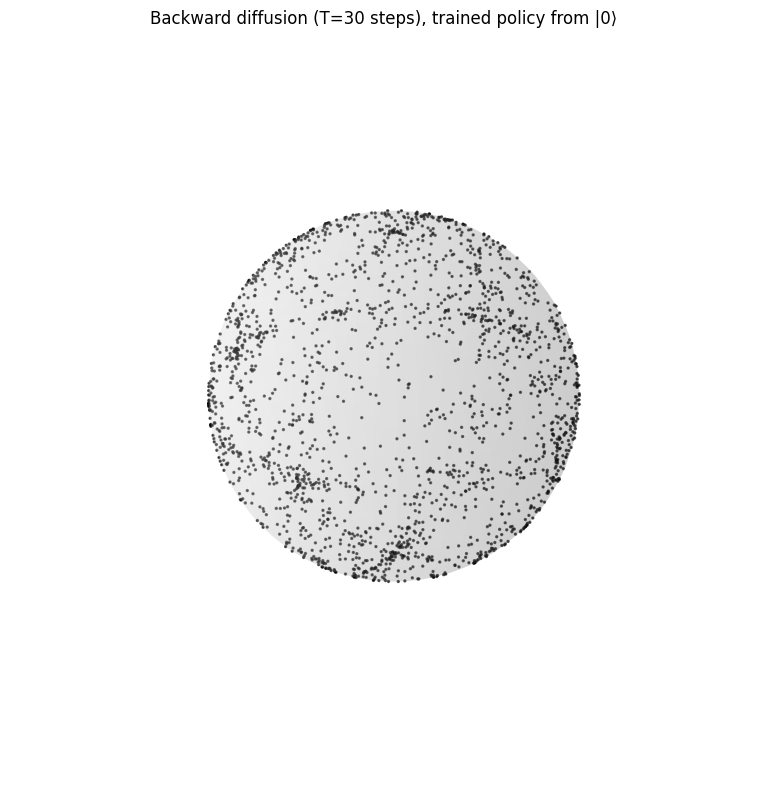

In [9]:
# Backward diffusion with trained policy: state distribution on Bloch sphere
# Requires: wm, fd, policy, initial_state, n_qubits, dim, T from cells above
import matplotlib.pyplot as plt
import numpy as np
from src import BackwardDiffusion, PAULI

def bloch_vector_batched(state):
    """Batched: ⟨ψ|σ|ψ⟩ via PAULI. state (..., 2) -> (..., 3)."""
    P = PAULI[1:4].to(state.device)
    return torch.einsum("...i,kij,...j->...k", state.conj(), P, state).real

T_bwd = T
n_traj_bwd = 2000

# Forward trajectory from |0⟩ to condition the policy
fd.state = initial_state.unsqueeze(0).expand(n_traj_bwd, -1).clone()
m_forward_seqs = fd.trajectory(T_bwd)  # (n_traj_bwd, T, n_qubits)

# Backward diffusion from random initial states
bd = BackwardDiffusion(wm, policy)
bd.forward_trajectory = m_forward_seqs
real = torch.randn(n_traj_bwd, dim, dtype=torch.float64, device=device)
imag = torch.randn(n_traj_bwd, dim, dtype=torch.float64, device=device)
states0 = (real + 1j * imag).to(torch.complex128)
states0 = states0 / (states0.abs()**2).sum(-1, keepdim=True).sqrt()
bd.state = states0

_ = bd.trajectory(T_bwd)  # bd.state now holds final (recovered) states
bloch = bloch_vector_batched(bd.state).cpu().numpy()

# Plot on Bloch sphere
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(bloch[:, 0], bloch[:, 1], bloch[:, 2], c="black", s=2, alpha=0.6)
u = np.linspace(0, 2 * np.pi, 50)
v = np.linspace(0, np.pi, 50)
xs = np.outer(np.cos(u), np.sin(v))
ys = np.outer(np.sin(u), np.sin(v))
zs = np.outer(np.ones(np.size(u)), np.cos(v))
ax.plot_surface(xs, ys, zs, alpha=0.15, color="lightgray")
ax.set_box_aspect([1, 1, 1])
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.set_zlim(-1.2, 1.2)
ax.axis("off")
ax.set_title(f"Backward diffusion (T={T_bwd} steps), trained policy from |0⟩")
plt.tight_layout()
plt.show()

**Why the plot above doesn't show concentration at the north pole**

The loss trains the policy so that **U_t K_t K_{t-1} ≈ c I** (local reversal). That means each U is tuned to "undo" the *same* forward path (the Kraus pair from the trajectory). But in the backward diffusion we **sample a new random weak measurement** at every step. So we're applying those reversal U's to states that were perturbed by *different* random measurements, not the forward path. We're not reversing the same trajectory—hence no concentration at |0⟩.

To see the policy actually recover |0⟩, we need **true reversal**: start from the *forward* final states (from |0⟩), then apply only the policy unitaries (no random measurement). The cell below does that and plots the result—states should concentrate near the north pole if the policy learned well.

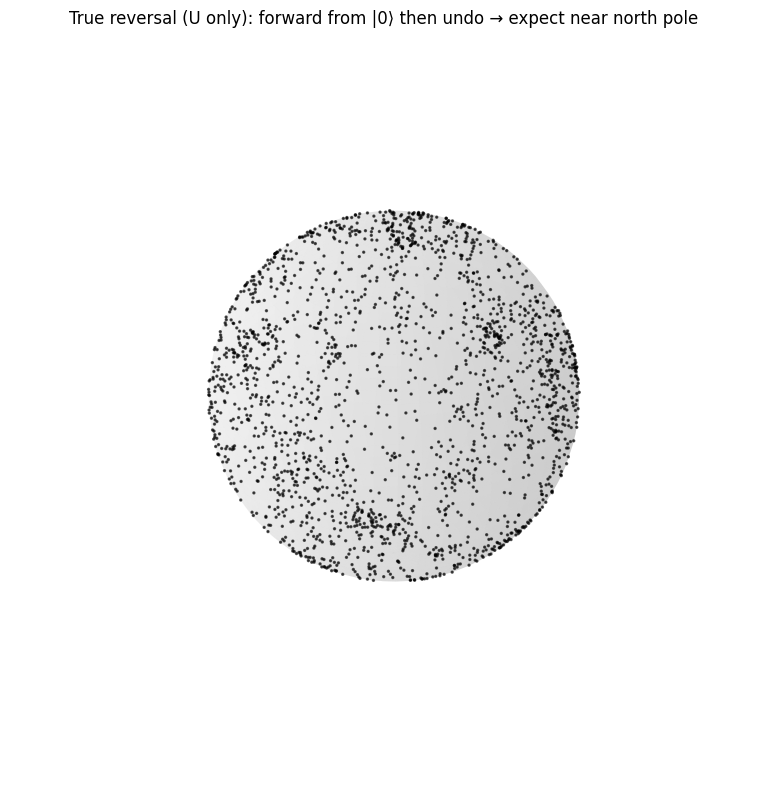

In [10]:
# True reversal: forward from |0⟩ then apply only U's (no random measurement)
# Uses same wm, fd, policy, initial_state, dim, T from above
n_traj_rev = 2000

# Forward from |0⟩ -> get trajectory and final states
fd.state = initial_state.unsqueeze(0).expand(n_traj_rev, -1).clone()
m_forward_seqs = fd.trajectory(T)  # (n_traj_rev, T, n_qubits); fd.state = final states

# Backward: start from those final states, apply only policy U's (T-1 steps; policy trained for t=1..T-1 only)
bd_rev = BackwardDiffusion(wm, policy)
bd_rev.forward_trajectory = m_forward_seqs
bd_rev.state = fd.state.clone()  # forward final states
_ = bd_rev.trajectory_reversal(T)  # runs T-1 steps -> bd_rev.state ≈ |0⟩

bloch_rev = bloch_vector_batched(bd_rev.state).cpu().numpy()

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(bloch_rev[:, 0], bloch_rev[:, 1], bloch_rev[:, 2], c="black", s=2, alpha=0.6)
u = np.linspace(0, 2 * np.pi, 50)
v = np.linspace(0, np.pi, 50)
xs = np.outer(np.cos(u), np.sin(v))
ys = np.outer(np.sin(u), np.sin(v))
zs = np.outer(np.ones(np.size(u)), np.cos(v))
ax.plot_surface(xs, ys, zs, alpha=0.15, color="lightgray")
ax.set_box_aspect([1, 1, 1])
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.set_zlim(-1.2, 1.2)
ax.axis("off")
ax.set_title("True reversal (U only): forward from |0⟩ then undo → expect near north pole")
plt.tight_layout()
plt.show()